# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

In [6]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp313-cp313-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-macosx_11_0_arm64.whl.metadata (5.2 kB)
Using cached matplotlib-3.11.2-cp313-cp313-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp313-cp313-macosx_11_0_arm64.whl (285 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 17.5 MB/s eta 0:00:00
Using cached kiwisolver-1.5.1-cp313-cp313-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 21.3 MB/s eta 0:00:0031m22.9 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [4]:

import random

class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def __str__(self):
        return f"{self.rank} of {self.suit}"


class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.create_deck()

    def create_deck(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6", "7",
                 "8", "9", "10", "J", "Q", "K"]

        self.cards = [
            Card(rank, suit)
            for _ in range(self.num_decks)
            for suit in suits
            for rank in ranks
        ]

        self.shuffle()

    def shuffle(self):
        random.shuffle(self.cards)
        self.plastic_position = random.randrange(len(self.cards))
        self.plastic_reached = False

    def draw(self):
        if not self.cards:
            raise ValueError("No cards left in the deck.")

        card = self.cards.pop()

        if len(self.cards) == self.plastic_position:
            self.plastic_reached = True

        return card

    def prepare_next_round(self):
        if self.plastic_reached or not self.cards:
            self.create_deck()


deck = Deck(6)

print("Number of cards:", len(deck.cards))
print("First card drawn:", deck.draw())
print("Cards remaining:", len(deck.cards))


Number of cards: 312
First card drawn: K of Diamonds
Cards remaining: 311


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [5]:
class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def get_value(self):
        pass


class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.plastic_position = 0

    def create_deck(self):
        pass

    def shuffle(self):
        pass

    def draw(self):
        pass

    def prepare_next_round(self):
        pass


class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        pass

    def get_value(self):
        pass

    def is_bust(self):
        pass


class Player:
    def __init__(self, name):
        self.name = name
        self.hand = Hand()

    def hit(self, deck):
        pass

    def stand(self):
        pass


class Dealer(Player):
    def __init__(self):
        super().__init__("Dealer")

    def play_turn(self, deck):
        pass


class BlackjackGame:
    def __init__(self, num_decks=6):
        self.deck = Deck(num_decks)
        self.player = Player("Player")
        self.dealer = Dealer()

    def start_round(self):
        pass

    def player_turn(self):
        pass

    def dealer_turn(self):
        pass

    def determine_winner(self):
        pass

    def play(self):
        pass

game = BlackjackGame()

print("Game created successfully!")
print("Player:", game.player.name)
print("Dealer:", game.dealer.name)
print("Number of decks:", game.deck.num_decks)


Game created successfully!
Player: Player
Dealer: Dealer
Number of decks: 6


4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [6]:

import random

class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def get_value(self):
        if self.rank == "A":
            return 11
        if self.rank in ["J", "Q", "K"]:
            return 10
        return int(self.rank)

    def __str__(self):
        return f"{self.rank} of {self.suit}"


class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.plastic_position = 0
        self.plastic_reached = False
        self.create_deck()

    def create_deck(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6",
                 "7", "8", "9", "10", "J", "Q", "K"]

        self.cards = [
            Card(rank, suit)
            for _ in range(self.num_decks)
            for suit in suits
            for rank in ranks
        ]
        self.shuffle()

    def shuffle(self):
        random.shuffle(self.cards)
        self.plastic_position = random.randint(
            1, len(self.cards) - 1
        )
        self.plastic_reached = False

    def draw(self):
        if not self.cards:
            self.create_deck()

        card = self.cards.pop()

        if len(self.cards) <= self.plastic_position:
            self.plastic_reached = True

        return card

    def prepare_next_round(self):
        if self.plastic_reached or len(self.cards) < 20:
            self.create_deck()


class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def get_value(self):
        total = sum(card.get_value() for card in self.cards)
        aces = sum(card.rank == "A" for card in self.cards)

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def is_bust(self):
        return self.get_value() > 21

    def is_blackjack(self):
        return len(self.cards) == 2 and self.get_value() == 21

    def __str__(self):
        return ", ".join(str(card) for card in self.cards)


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    def hit(self, deck):
        self.hand.add_card(deck.draw())

    def stand(self):
        return False

    def place_bet(self, amount):
        if amount <= 0 or amount > self.chips:
            raise ValueError("Invalid bet amount.")

        self.bet = amount
        self.chips -= amount

    def reset_hand(self):
        self.hand = Hand()
        self.bet = 0


class Dealer(Player):
    def __init__(self):
        super().__init__("Dealer", 0)

    def play_turn(self, deck):
        print("\nDealer's turn:")
        print("Dealer's hand:", self.hand)

        while self.hand.get_value() < 17:
            self.hit(deck)
            print("Dealer hits:", self.hand.cards[-1])

        print("Dealer's final value:", self.hand.get_value())


class BlackjackGame:
    def __init__(self, num_decks=6, starting_chips=100):
        self.deck = Deck(num_decks)
        self.player = Player("Human", starting_chips)
        self.dealer = Dealer()
        self.round_number = 0
        self.shown_cards = []

    def show_card(self, card):
        self.shown_cards.append(card)

    def deal_visible_card(self, person):
        person.hit(self.deck)
        self.show_card(person.hand.cards[-1])

    def start_round(self):
        if self.player.chips <= 0:
            print("You have no chips remaining!")
            return False

        self.deck.prepare_next_round()
        self.player.reset_hand()
        self.dealer.reset_hand()

        self.round_number += 1
        print(f"\n===== ROUND {self.round_number} =====")
        print("Available chips:", self.player.chips)

        while True:
            try:
                bet = float(input("Enter your bet: "))
                self.player.place_bet(bet)
                break
            except ValueError:
                print("Enter a valid bet within your balance.")

        for _ in range(2):
            self.deal_visible_card(self.player)
            self.dealer.hit(self.deck)

        self.show_card(self.dealer.hand.cards[0])

        print("\nYour hand:", self.player.hand)
        print("Your total:", self.player.hand.get_value())
        print("Dealer shows:", self.dealer.hand.cards[0])

        return True

    def player_turn(self):
        if self.player.hand.is_blackjack():
            print("Blackjack! Your turn ends.")
            return

        while not self.player.hand.is_bust():
            choice = input("Hit or Stand? (h/s): ").lower().strip()

            if choice == "h":
                self.deal_visible_card(self.player)
                print("Your hand:", self.player.hand)
                print("Your total:", self.player.hand.get_value())

                if self.player.hand.is_bust():
                    print("You busted!")
                    break

            elif choice == "s":
                print("You stand.")
                break

            else:
                print("Invalid choice. Enter h or s.")

    def dealer_turn(self):
        self.show_card(self.dealer.hand.cards[1])

        print("\nDealer reveals:", self.dealer.hand)

        if self.player.hand.is_bust():
            return

        if self.player.hand.is_blackjack():
            return

        if self.dealer.hand.is_blackjack():
            return

        while self.dealer.hand.get_value() < 17:
            self.deal_visible_card(self.dealer)
            print("Dealer hits:", self.dealer.hand.cards[-1])

        print("Dealer's final total:", self.dealer.hand.get_value())

    def determine_winner(self):
        player_value = self.player.hand.get_value()
        dealer_value = self.dealer.hand.get_value()
        bet = self.player.bet

        player_blackjack = self.player.hand.is_blackjack()
        dealer_blackjack = self.dealer.hand.is_blackjack()

        if player_blackjack and dealer_blackjack:
            result = "Push! Both have blackjack."
            payout = bet

        elif player_blackjack:
            result = "Blackjack! You win!"
            payout = bet * 2.5

        elif dealer_blackjack:
            result = "Dealer has blackjack. You lose."
            payout = 0

        elif player_value > 21:
            result = "You busted. Dealer wins."
            payout = 0

        elif dealer_value > 21:
            result = "Dealer busted. You win!"
            payout = bet * 2

        elif player_value > dealer_value:
            result = "You win!"
            payout = bet * 2

        elif player_value < dealer_value:
            result = "Dealer wins."
            payout = 0

        else:
            result = "Push! It's a tie."
            payout = bet

        self.player.chips += payout

        print("\nResult:", result)
        print("Your total:", player_value)
        print("Dealer total:", dealer_value)
        print("Chips remaining:", self.player.chips)

        return result

    def play(self):
        print("Welcome to Blackjack!")

        while self.player.chips > 0:
            if not self.start_round():
                break

            if not self.dealer.hand.is_blackjack():
                self.player_turn()

            self.dealer_turn()
            self.determine_winner()

            if self.player.chips <= 0:
                print("\nGame over! You are out of chips.")
                break

            again = input("\nPlay another round? (y/n): ")
            if again.lower().strip() != "y":
                break

        print("\nThank you for playing!")
        print("Final chips:", self.player.chips)


game = BlackjackGame(num_decks=6, starting_chips=100)
game.play()


Welcome to Blackjack!

===== ROUND 1 =====
Available chips: 100


Enter your bet:  45



Your hand: J of Hearts, 5 of Clubs
Your total: 15
Dealer shows: 5 of Diamonds


Hit or Stand? (h/s):  h


Your hand: J of Hearts, 5 of Clubs, 8 of Diamonds
Your total: 23
You busted!

Dealer reveals: 5 of Diamonds, 4 of Diamonds

Result: You busted. Dealer wins.
Your total: 23
Dealer total: 9
Chips remaining: 55.0



Play another round? (y/n):  n



Thank you for playing!
Final chips: 55.0


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [7]:

import random

game = BlackjackGame(num_decks=6, starting_chips=100)

for round_number in range(1, 6):
    game.deck.prepare_next_round()
    game.player.reset_hand()
    game.dealer.reset_hand()

    game.player.place_bet(10)

    for _ in range(2):
        game.deal_visible_card(game.player)
        game.dealer.hit(game.deck)

    game.show_card(game.dealer.hand.cards[0])

    print(f"\n========== ROUND {round_number} ==========")
    print("Player's hand:", game.player.hand)
    print("Player's total:", game.player.hand.get_value())
    print("Dealer shows:", game.dealer.hand.cards[0])

    if not game.player.hand.is_blackjack() and not game.dealer.hand.is_blackjack():
        while game.player.hand.get_value() < 17:
            game.deal_visible_card(game.player)
            print("Player hits:", game.player.hand.cards[-1])

    game.dealer_turn()

    print("Final player hand:", game.player.hand)
    print("Final dealer hand:", game.dealer.hand)

    game.determine_winner()

print("\n========== GAME SUMMARY ==========")
print("Rounds played:", round_number)
print("Starting chips: 100")
print("Final chips:", game.player.chips)
print("Net profit/loss:", game.player.chips - 100)



========== ROUND 1 ==========
Player's hand: 2 of Clubs, Q of Hearts
Player's total: 12
Dealer shows: 8 of Clubs
Player hits: 5 of Spades

Dealer reveals: 8 of Clubs, 6 of Diamonds
Dealer hits: 4 of Diamonds
Dealer's final total: 18
Final player hand: 2 of Clubs, Q of Hearts, 5 of Spades
Final dealer hand: 8 of Clubs, 6 of Diamonds, 4 of Diamonds

Result: Dealer wins.
Your total: 17
Dealer total: 18
Chips remaining: 90

========== ROUND 2 ==========
Player's hand: K of Diamonds, A of Clubs
Player's total: 21
Dealer shows: A of Clubs

Dealer reveals: A of Clubs, Q of Spades
Final player hand: K of Diamonds, A of Clubs
Final dealer hand: A of Clubs, Q of Spades

Result: Push! Both have blackjack.
Your total: 21
Dealer total: 21
Chips remaining: 90

========== ROUND 3 ==========
Player's hand: 4 of Hearts, 5 of Hearts
Player's total: 9
Dealer shows: 7 of Clubs
Player hits: 6 of Hearts
Player hits: 4 of Clubs

Dealer reveals: 7 of Clubs, A of Hearts
Dealer's final total: 18
Final player h

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [8]:

import random
import numpy as np
import matplotlib.pyplot as plt

class CountingPlayer(Player):
    def __init__(self, name="Counter", chips=100, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold

    def wants_hit(self, running_count):
        return running_count < self.threshold


class DealerStylePlayer(Player):
    def wants_hit(self, running_count):
        return self.hand.get_value() < 17


def count_value(card):
    if card.rank in ("2", "3", "4", "5", "6"):
        return 1
    if card.rank in ("7", "8", "9"):
        return 0
    return -1


class SimulationBlackjack:
    def __init__(self, threshold=0, strategy="count",
                 starting_chips=100, bet_size=5, num_decks=6):

        self.deck = Deck(num_decks)
        self.counter = CountingPlayer("Counter", starting_chips, threshold)
        self.others = [
            DealerStylePlayer(f"Computer {i}", starting_chips)
            for i in range(1, 4)
        ]
        self.players = [self.counter] + self.others
        self.dealer = Dealer()
        self.running_count = 0
        self.bet_size = bet_size
        self.strategy = strategy

    def reveal(self, card):
        self.running_count += count_value(card)

    def draw_visible(self, player):
        card = self.deck.draw()
        player.hand.add_card(card)
        self.reveal(card)

    def counter_hits(self):
        total = self.counter.hand.get_value()

        if self.strategy == "hybrid":
            if total <= 11:
                return True
            if total >= 17:
                return False

        return self.counter.wants_hit(self.running_count)

    def play_round(self):
        active = [p for p in self.players if p.chips > 0]

        if not active:
            return

        needs_shuffle = (
            self.deck.plastic_reached or len(self.deck.cards) < 20
        )

        self.deck.prepare_next_round()

        if needs_shuffle:
            self.running_count = 0

        self.dealer.reset_hand()

        for player in active:
            player.reset_hand()
            player.place_bet(min(self.bet_size, player.chips))

        for _ in range(2):
            for player in active:
                self.draw_visible(player)
            self.dealer.hit(self.deck)

        self.reveal(self.dealer.hand.cards[0])

        dealer_blackjack = self.dealer.hand.is_blackjack()

        if not dealer_blackjack:
            for player in active:
                if player.hand.is_blackjack():
                    continue

                while not player.hand.is_bust():
                    if player is self.counter:
                        hit = self.counter_hits()
                    else:
                        hit = player.wants_hit(self.running_count)

                    if not hit:
                        break

                    self.draw_visible(player)

        self.reveal(self.dealer.hand.cards[1])

        remaining = any(
            not p.hand.is_bust() and not p.hand.is_blackjack()
            for p in active
        )

        if not dealer_blackjack and remaining:
            while self.dealer.hand.get_value() < 17:
                self.draw_visible(self.dealer)

        for player in active:
            wager = player.bet
            player_bj = player.hand.is_blackjack()
            dealer_bj = self.dealer.hand.is_blackjack()

            if player_bj and dealer_bj:
                payout = wager

            elif player_bj:
                payout = 2.5 * wager

            elif dealer_bj or player.hand.is_bust():
                payout = 0

            elif self.dealer.hand.is_bust():
                payout = 2 * wager

            elif player.hand.get_value() > self.dealer.hand.get_value():
                payout = 2 * wager

            elif player.hand.get_value() == self.dealer.hand.get_value():
                payout = wager

            else:
                payout = 0

            player.chips += payout


def run_simulation(threshold=0, rounds=50,
                   strategy="count", seed=None):

    if seed is not None:
        random.seed(seed)

    game = SimulationBlackjack(
        threshold=threshold,
        strategy=strategy
    )

    history = [game.counter.chips]

    for _ in range(rounds):
        if game.counter.chips <= 0:
            break

        game.play_round()
        history.append(game.counter.chips)

    return game.counter.chips, history


def run_100(threshold=0, strategy="count"):
    return [
        run_simulation(
            threshold=threshold,
            rounds=50,
            strategy=strategy,
            seed=2026 + i
        )[0]
        for i in range(100)
    ]


player = CountingPlayer(threshold=0)

print("Player:", player.name)
print("Threshold:", player.threshold)
print("Card 5 count:", count_value(Card("5", "Hearts")))
print("Card 8 count:", count_value(Card("8", "Spades")))
print("Card K count:", count_value(Card("K", "Clubs")))
print("Hit with count -2:", player.wants_hit(-2))
print("Hit with count +3:", player.wants_hit(3))


Player: Counter
Threshold: 0
Card 5 count: 1
Card 8 count: 0
Card K count: -1
Hit with count -2: True
Hit with count +3: False


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [10]:

game = SimulationBlackjack(
    threshold=0,
    starting_chips=100,
    bet_size=5,
    num_decks=6
)

starting_chips = game.counter.chips
rounds_played = 0

for i in range(50):
    if game.counter.chips <= 0:
        break

    game.play_round()
    rounds_played += 1

final_chips = game.counter.chips
net_winnings = final_chips - starting_chips

print("========== QUESTION 7 RESULTS ==========")
print("Number of players:", len(game.players))
print("Number of dealer-style players:", len(game.others))
print("Starting chips:", starting_chips)
print("Rounds played:", rounds_played)
print("Final chips:", final_chips)
print("Strategy player's net winnings:", net_winnings)

if net_winnings > 0:
    print("Result: The strategy player made a profit.")
elif net_winnings < 0:
    print("Result: The strategy player lost money.")
else:
    print("Result: The strategy player broke even.")



========== QUESTION 7 RESULTS ==========
Number of players: 4
Number of dealer-style players: 3
Starting chips: 100
Rounds played: 36
Final chips: 0.0
Strategy player's net winnings: -100.0
Result: The strategy player lost money.


## 8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Number of simulations: 100
Average final chips: 11.62
Average net winnings: -88.38
Average winnings per scheduled round: -1.7675
Standard deviation: 22.71
Probability of net winning: 0.0
Probability of net losing: 0.99
Probability of breaking even: 0.01


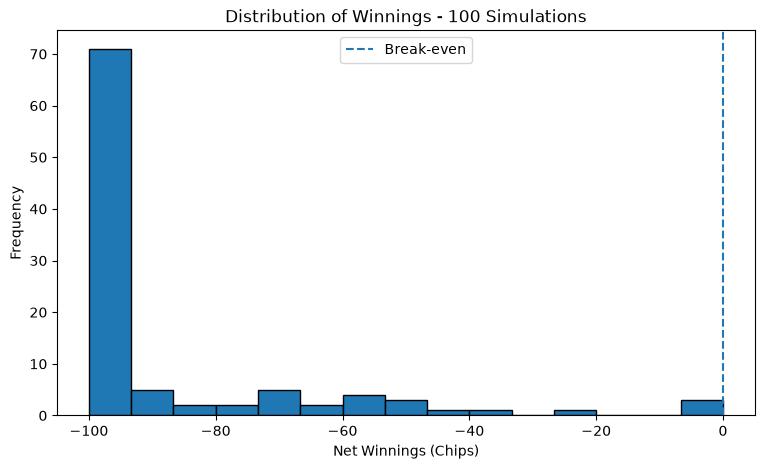

In [11]:

results = np.array(run_100(threshold=0))

net_winnings = results - 100

average_winnings = np.mean(net_winnings)
average_per_round = np.mean(net_winnings) / 50
standard_deviation = np.std(net_winnings)

probability_win = np.mean(net_winnings > 0)
probability_loss = np.mean(net_winnings < 0)
probability_tie = np.mean(net_winnings == 0)

print("Number of simulations:", len(results))
print("Average final chips:", round(np.mean(results), 2))
print("Average net winnings:", round(average_winnings, 2))
print("Average winnings per scheduled round:",
      round(average_per_round, 4))
print("Standard deviation:", round(standard_deviation, 2))
print("Probability of net winning:", round(probability_win, 4))
print("Probability of net losing:", round(probability_loss, 4))
print("Probability of breaking even:", round(probability_tie, 4))

plt.figure(figsize=(9, 5))
plt.hist(net_winnings, bins=15, edgecolor="black")
plt.axvline(0, linestyle="--", label="Break-even")
plt.xlabel("Net Winnings (Chips)")
plt.ylabel("Frequency")
plt.title("Distribution of Winnings - 100 Simulations")
plt.legend()
plt.show()


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?


Threshold: -5
Average net winnings: -62.7
Standard deviation: 33.99
Winning probability: 0.05

Threshold: -2
Average net winnings: -80.25
Standard deviation: 26.57
Winning probability: 0.01

Threshold: 0
Average net winnings: -88.38
Standard deviation: 22.71
Winning probability: 0.0

Threshold: 2
Average net winnings: -95.9
Standard deviation: 13.42
Winning probability: 0.0

Threshold: 5
Average net winnings: -99.2
Standard deviation: 4.61
Winning probability: 0.0

Best threshold tested: -5
Highest average net winnings: -62.7


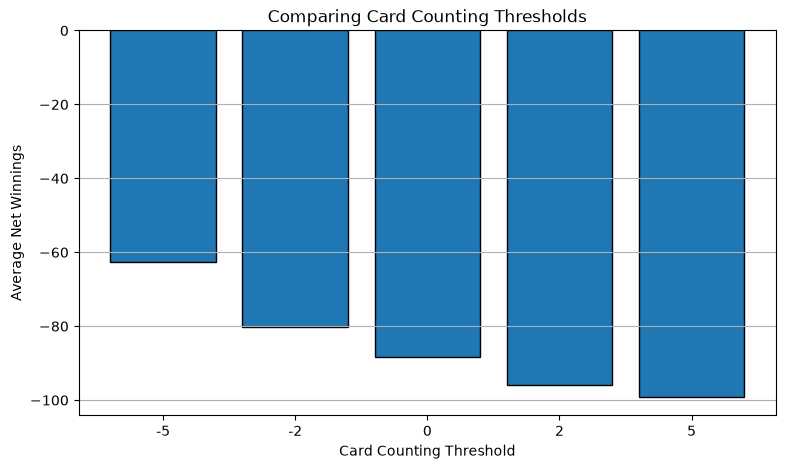

In [12]:

thresholds = [-5, -2, 0, 2, 5]

average_results = []
standard_deviations = []
win_probabilities = []

for threshold in thresholds:
    results = np.array(run_100(threshold=threshold))
    net_winnings = results - 100

    average_results.append(np.mean(net_winnings))
    standard_deviations.append(np.std(net_winnings))
    win_probabilities.append(np.mean(net_winnings > 0))

    print(f"\nThreshold: {threshold}")
    print("Average net winnings:",
          round(np.mean(net_winnings), 2))
    print("Standard deviation:",
          round(np.std(net_winnings), 2))
    print("Winning probability:",
          round(np.mean(net_winnings > 0), 4))

best_index = np.argmax(average_results)
best_threshold = thresholds[best_index]

print("\nBest threshold tested:", best_threshold)
print("Highest average net winnings:",
      round(average_results[best_index], 2))

plt.figure(figsize=(9, 5))
plt.bar([str(t) for t in thresholds], average_results,
        edgecolor="black")
plt.xlabel("Card Counting Threshold")
plt.ylabel("Average Net Winnings")
plt.title("Comparing Card Counting Thresholds")
plt.grid(axis="y")
plt.show()


10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

Original strategy:
Average net winnings: -62.7
Winning probability: 0.05

New hybrid strategy:
Average net winnings: -15.25
Winning probability: 0.34

Difference in average winnings: 47.45
The new strategy performed better in this experiment.


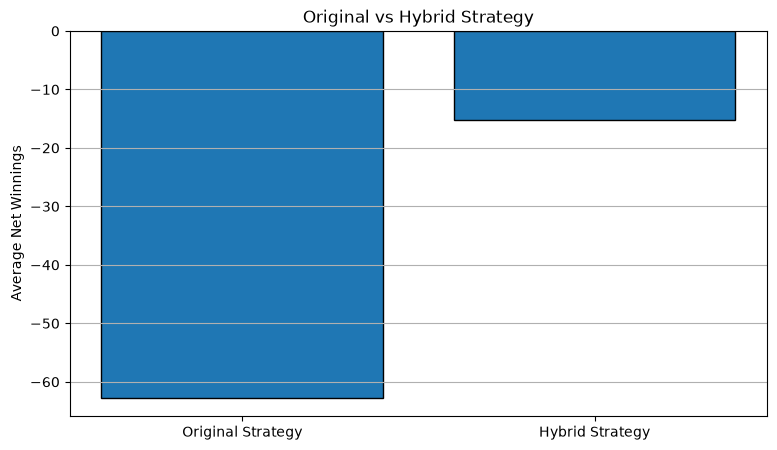

In [13]:

original_results = np.array(
    run_100(threshold=best_threshold, strategy="count")
)

new_results = np.array(
    run_100(threshold=best_threshold, strategy="hybrid")
)

original_net = original_results - 100
new_net = new_results - 100

original_average = np.mean(original_net)
new_average = np.mean(new_net)
difference = new_average - original_average

print("Original strategy:")
print("Average net winnings:", round(original_average, 2))
print("Winning probability:",
      round(np.mean(original_net > 0), 4))

print("\nNew hybrid strategy:")
print("Average net winnings:", round(new_average, 2))
print("Winning probability:",
      round(np.mean(new_net > 0), 4))

print("\nDifference in average winnings:",
      round(difference, 2))

if difference > 0:
    print("The new strategy performed better in this experiment.")
elif difference < 0:
    print("The new strategy performed worse in this experiment.")
else:
    print("Both strategies had equal average winnings.")

plt.figure(figsize=(9, 5))
plt.bar(
    ["Original Strategy", "Hybrid Strategy"],
    [original_average, new_average],
    edgecolor="black"
)
plt.ylabel("Average Net Winnings")
plt.title("Original vs Hybrid Strategy")
plt.grid(axis="y")
plt.show()
